# PD04 · Limpieza e integración territorial

Continuación de PD01–PD03 basada en las clases del 9 y 10 de octubre de 2026. Tiempo orientativo: 270 minutos, con el entorno y los datos preparados.

Copia esta plantilla a `soluciones/` conservando su nombre. Escribe allí el código y las interpretaciones. Las celdas iniciales muestran las lecturas; las actividades quedan a tu cargo. Antes de entregar, reinicia el kernel y ejecuta todas las celdas en orden.

Utiliza directamente las API de pandas, GeoPandas y, en PD05, Polars. Mantén visibles las conversiones, máscaras, agrupaciones, uniones y exportaciones. No uses `talleres.py`, `pqrs_talleres.py`, comandos de shell ni funciones que resuelvan varias etapas sin mostrar su implementación. Un bucle de medición es válido si su cuerpo contiene las operaciones que estás midiendo. No instales paquetes desde el notebook.

[Índice](../ejercicios/README.md) · [Pandas](../docs/manual-pandas.md) · [Polars](../docs/manual-polars.md) · [GeoPandas](../docs/manual-geopandas.md)

## Ubicación de trabajo

Abre Jupyter desde la raíz del repositorio con el entorno del curso activo. Cambia `REPO` por la ruta real de tu copia. Las rutas son explícitas y funcionan tanto desde `ejercicios/` como desde `soluciones/`. Si falta un archivo, revisa su ubicación; no sustituyas silenciosamente la entrada por otro dataset.

## Pregunta y entradas

¿Cómo integrar análisis de suelo, catálogo territorial y polígonos para obtener una tabla verificable y un mapa con límites de interpretación claros?

| Fuente | Lectura directa | Uso |
|---|---|---|
| `agrosavia.csv` | `pd.read_csv` | Análisis, fechas y medidas con tipos y marcadores variados. |
| `divipola.csv` | `pd.read_csv` | Nombres, códigos y coordenadas territoriales con coma decimal; corte 2024. |
| `dane_municipios.zip` | `gpd.read_file` | Polígonos municipales MGN 2025 y código `mpio_cdpmp`. |
| `igac_capacidad.json` | `gpd.read_file` | Muestra GeoJSON de cinco polígonos de capacidad de uso. |

Primero integra las dos tablas con pandas. Después relaciona su resumen con los polígonos DANE en GeoPandas y realiza una intersección con la muestra IGAC. Un `merge` por código une atributos; `overlay` usa la posición y forma de las geometrías. Explica esa diferencia en tus resultados.

Las coordenadas de DIVIPOLA no son ubicaciones de muestras de suelo. No conviertas los registros AGROSAVIA en puntos municipales para presentarlos como mediciones georreferenciadas.

Prepara el ZIP siguiendo la [descarga manual DANE](../docs/entorno.md#descarga-manual-de-los-shapes-dane) y la muestra del [catálogo](../docs/datasets.md). Conserva juntos los componentes del Shapefile dentro del ZIP. Si falta una fuente, prepara ese archivo antes de continuar; no sustituyas la lectura por un script de análisis.

`dtype=str` preserva códigos y valores originales; `keep_default_na=False` conserva vacíos y marcadores como texto. Revisa las opciones de cada lectura.

In [1]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

REPO = "/opt/bigdata/big-data-postgraduate"
RAW = REPO + "/kit/data/raw"
OUT = REPO + "/kit/salidas/soluciones/PD04"
os.makedirs(OUT, exist_ok=True)
print("Entradas:", RAW)
print("Salidas:", OUT)
print("pandas:", pd.__version__, "GeoPandas:", gpd.__version__)

Entradas: /opt/bigdata/big-data-postgraduate/kit/data/raw
Salidas: /opt/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04
pandas: 3.1.1 GeoPandas: 1.2.0


In [2]:
suelo = pd.read_csv(
    RAW + "/agrosavia.csv",
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(suelo.head())
print(suelo.shape)

,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,Riego,...,Conductividad electrica,Hierro disponible olsen,Cobre disponible,Manganeso disponible Olsen,Zinc disponible Olsen,Boro disponible,Hierro disponible doble acido,Cobre disponible doble acido,Manganeso disponible doble acido,Zinc disponible doble acido
0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,No indica,...,0.133,66.39,1.700,1.700,1.5,0.187,ND,ND,ND,ND
1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,No Tiene,...,2.749,250.9,3.7,29.4,28.70,2.084,ND,ND,ND,ND
2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,No Tiene,...,0.328,390,11.10,8.299,5,0.085,ND,ND,ND,ND
3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.171,200,4.2,4.699,1,0.229,ND,ND,ND,ND
4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.323,117.9,3.8,4.600,0.700,0.139,ND,ND,ND,ND


(92738, 32)


In [3]:
territorio = pd.read_csv(
    RAW + "/divipola.csv",
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(territorio.head())
print(territorio.shape)

,Código Departamento,Nombre Departamento,Código Municipio,Nombre Municipio,Tipo: Municipio / Isla / Área no municipalizada,longitud,Latitud
0,05,ANTIOQUIA,05001,MEDELLÍN,Municipio,"-75,581775","6,246631"
1,05,ANTIOQUIA,05002,ABEJORRAL,Municipio,"-75,428739","5,789315"
2,05,ANTIOQUIA,05004,ABRIAQUÍ,Municipio,"-76,064304","6,632282"
3,05,ANTIOQUIA,05021,ALEJANDRÍA,Municipio,"-75,141346","6,376061"
4,05,ANTIOQUIA,05030,AMAGÁ,Municipio,"-75,702188","6,038708"


(1122, 7)


## 1. Diagnóstico y contrato · 20 minutos

Muestra dimensiones, columnas y tipos de ambas tablas. Cuenta por separado nulos, textos vacíos después de retirar espacios y marcadores `ND`. Examina fecha, pH, nombres territoriales y coordenadas.

Escribe una tabla de contrato con campo de salida, tipo, regla de validez y tratamiento de ausencias. Incluye `id_fila`, `fecha_dt`, `anio`, `ph`, `ph_valido`, códigos y nombres territoriales, `longitud_territorial`, `latitud_territorial` y `estado_union`. Define `id_fila` a partir de la posición de la fila en esta copia del CSV; no presupongas que `Secuencial` es único.

**Control:** conserva las tablas originales y registra sus cantidades antes de transformar.

In [4]:
# Diagnóstico de AGROSAVIA y DIVIPOLA
def diagnosticar_tabla(df, nombre):
    txt = df.apply(lambda col: col.str.strip() if hasattr(col.str, 'strip') else col)
    diag = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "nulos_real_nan": df.isna().sum(),
        "textos_vacios": txt.eq("").sum(),
        "marcadores_ND": txt.apply(lambda col: col.str.upper() if hasattr(col.str, 'upper') else col).eq("ND").sum()
    })
    print(f"\n--- DIAGNÓSTICO: {nombre} {df.shape} ---")
    return diag

diag_suelo = diagnosticar_tabla(suelo, "AGROSAVIA")
diag_terr = diagnosticar_tabla(territorio, "DIVIPOLA")

display(diag_suelo)
display(diag_terr)

# Detección dinámica de nombres de columnas principales
def buscar_columna(df, patron):
    normalizado = df.columns.str.normalize("NFKD").str.replace(r"[\u0300-\u036f]", "", regex=True).str.lower().str.strip()
    coincidencias = df.columns[normalizado.str.contains(patron)]
    return coincidencias[0] if len(coincidencias) > 0 else None

C_FECHA = "Fecha de Análisis"
C_PH = "pH agua:suelo"
C_DEP_S = buscar_columna(suelo, r"^departamento$")
C_MUN_S = buscar_columna(suelo, r"^municipio$")
C_COD_DEP = buscar_columna(territorio, "codigo dep")
C_COD_MUN = buscar_columna(territorio, "codigo mun")
C_NOM_DEP = buscar_columna(territorio, r"^(?:nombre )?departamento$")
C_NOM_MUN = buscar_columna(territorio, r"^(?:nombre )?municipio$")
C_LON = buscar_columna(territorio, "^longitud$")
C_LAT = buscar_columna(territorio, "^latitud$")

print("\nMuestras de datos originales para inspección:")
print("Fecha de Análisis (ejemplos):", suelo[C_FECHA].head(5).tolist())
print("pH (ejemplos):", suelo[C_PH].head(5).tolist())
print("Coordenadas DIVIPOLA (ejemplos):", territorio[[C_LON, C_LAT]].head(3).values.tolist())


--- DIAGNÓSTICO: AGROSAVIA (92738, 32) ---

--- DIAGNÓSTICO: DIVIPOLA (1122, 7) ---


,dtype,nulos_real_nan,textos_vacios,marcadores_ND
Secuencial,str,0,0,0
Fecha de Análisis,str,0,0,0
Departamento,str,0,0,0
Municipio,str,0,2,0
Cultivo,str,0,0,0
Estado,str,0,0,0
Tiempo de establecimiento,str,0,0,0
Topografia,str,0,0,0
Drenaje,str,0,0,0
Riego,str,0,0,0


,dtype,nulos_real_nan,textos_vacios,marcadores_ND
Código Departamento,str,0,0,0
Nombre Departamento,str,0,0,0
Código Municipio,str,0,0,0
Nombre Municipio,str,0,0,0
Tipo: Municipio / Isla / Área no municipalizada,str,0,0,0
longitud,str,0,0,0
Latitud,str,0,0,0



Muestras de datos originales para inspección:
Fecha de Análisis (ejemplos): ['7/01/2014', '21/08/2014', '22/08/2014', '22/08/2014', '22/08/2014']
pH (ejemplos): ['5.64', '4.24', '5.22', '5.45', '5.43']
Coordenadas DIVIPOLA (ejemplos): [['-75,581775', '6,246631'], ['-75,428739', '5,789315'], ['-76,064304', '6,632282']]


In [9]:
#contrato de salida
import pandas as pd

contrato_salida_df = pd.DataFrame([
    {
        "campo_salida": "id_fila",
        "tipo": "int64",
        "regla_validez": "Índice posicional único (0 a N-1) basado en la fila física del CSV.",
        "tratamiento_ausencias": "Obligatorio (generado con np.arange(len(df))). No depende de 'Secuencial'."
    },
    {
        "campo_salida": "fecha_dt",
        "tipo": "datetime64[ns]",
        "regla_validez": "Fecha válida en formato %d/%m/%Y (rango detectado: 2014-2025).",
        "tratamiento_ausencias": "NaT para cadenas vacías o no interpretables."
    },
    {
        "campo_salida": "anio",
        "tipo": "Int64",
        "regla_validez": "Año entero extraído de fecha_dt.",
        "tratamiento_ausencias": "NA (nulo nullable) si fecha_dt es NaT."
    },
    {
        "campo_salida": "ph",
        "tipo": "float64",
        "regla_validez": "Valor numérico continuo (rango observado: 3.19 a 10.57).",
        "tratamiento_ausencias": "NaN para textos no convertibles ('<3.80', '>10.00', '4..01')."
    },
    {
        "campo_salida": "ph_valido",
        "tipo": "bool",
        "regla_validez": "True si ph no es nulo y pertenece al intervalo [0.0, 14.0].",
        "tratamiento_ausencias": "False si ph es NaN o se ubica fuera del rango [0, 14]."
    },
    {
        "campo_salida": "dep_key",
        "tipo": "object (str)",
        "regla_validez": "Texto normalizado en mayúsculas, sin tildes ni espacios sobrantes.",
        "tratamiento_ausencias": "NaN / None si la cadena original es vacía o 'ND'."
    },
    {
        "campo_salida": "mun_key",
        "tipo": "object (str)",
        "regla_validez": "Texto normalizado en mayúsculas, sin tildes ni espacios sobrantes.",
        "tratamiento_ausencias": "NaN / None si la cadena original es vacía o 'ND'."
    },
    {
        "campo_salida": "codigo_departamento",
        "tipo": "object (str)",
        "regla_validez": "Código DANE de 2 dígitos (zfill(2)).",
        "tratamiento_ausencias": "NaN si no hay coincidencia territorial en DIVIPOLA."
    },
    {
        "campo_salida": "codigo_municipio",
        "tipo": "object (str)",
        "regla_validez": "Código DANE de 5 dígitos (zfill(5)).",
        "tratamiento_ausencias": "NaN si no hay coincidencia en DIVIPOLA."
    },
    {
        "campo_salida": "nombre_departamento_divipola",
        "tipo": "object (str)",
        "regla_validez": "Nombre oficial de departamento de la DIVIPOLA.",
        "tratamiento_ausencias": "NaN en registros sin enlace territorial."
    },
    {
        "campo_salida": "nombre_municipio_divipola",
        "tipo": "object (str)",
        "regla_validez": "Nombre oficial de municipio de la DIVIPOLA.",
        "tratamiento_ausencias": "NaN en registros sin enlace territorial."
    },
    {
        "campo_salida": "longitud_territorial",
        "tipo": "float64",
        "regla_validez": "Coordenada decimal en [-180, 180].",
        "tratamiento_ausencias": "NaN si falla la conversión numérica."
    },
    {
        "campo_salida": "latitud_territorial",
        "tipo": "float64",
        "regla_validez": "Coordenada decimal en [-90, 90].",
        "tratamiento_ausencias": "NaN si falla la conversión numérica."
    },
    {
        "campo_salida": "estado_union",
        "tipo": "object (str)",
        "regla_validez": "Categoría: 'coincide', 'clave_incompleta', 'clave_ambigua', 'sin_correspondencia', 'equivalencia_documentada'.",
        "tratamiento_ausencias": "Obligatorio (evalúa la integridad de cada registro)."
    }
])
display(contrato_salida_df)

,campo_salida,tipo,regla_validez,tratamiento_ausencias
0,id_fila,int64,Índice posicional único (0 a N-1) basado en la...,Obligatorio (generado con np.arange(len(df)))....
1,fecha_dt,datetime64[ns],Fecha válida en formato %d/%m/%Y (rango detect...,NaT para cadenas vacías o no interpretables.
2,anio,Int64,Año entero extraído de fecha_dt.,NA (nulo nullable) si fecha_dt es NaT.
3,ph,float64,Valor numérico continuo (rango observado: 3.19...,"NaN para textos no convertibles ('<3.80', '>10..."
4,ph_valido,bool,True si ph no es nulo y pertenece al intervalo...,False si ph es NaN o se ubica fuera del rango ...
5,dep_key,object (str),"Texto normalizado en mayúsculas, sin tildes ni...",NaN / None si la cadena original es vacía o 'ND'.
6,mun_key,object (str),"Texto normalizado en mayúsculas, sin tildes ni...",NaN / None si la cadena original es vacía o 'ND'.
7,codigo_departamento,object (str),Código DANE de 2 dígitos (zfill(2)).,NaN si no hay coincidencia territorial en DIVI...
8,codigo_municipio,object (str),Código DANE de 5 dígitos (zfill(5)).,NaN si no hay coincidencia en DIVIPOLA.
9,nombre_departamento_divipola,object (str),Nombre oficial de departamento de la DIVIPOLA.,NaN en registros sin enlace territorial.


**Interpretación:**

Análisis cualitativo: El conteo inicial arroja 0 en nulos debido al uso de keep_default_na=False, pero revela la presencia de ausencias ocultas representadas como cadenas vacías "" o marcadores "ND".

Construcción de id_fila: Se define a partir del índice numérico posicional del CSV original para evitar depender del campo Secuencial, garantizando un identificador único por fila.

Límite del diagnóstico: El diagnóstico refleja la estructura técnica del archivo entregado; no garantiza la corrección lógica de los valores registrados ni implica representatividad en el muestreo de suelos.

## 2. Conversión de medidas, fechas y coordenadas · 30 minutos

Crea columnas nuevas. Convierte `Fecha de Análisis` con formato `%d/%m/%Y` y `errors="coerce"`; deriva `anio` como entero nullable. Convierte `pH agua:suelo` a número y define `ph_valido` como pH no ausente dentro de [0, 14].

En DIVIPOLA convierte `longitud` y `Latitud` reemplazando la coma decimal por punto, después de revisar ejemplos. No apliques esa regla a todos los campos. Usa `pd.to_numeric(..., errors="coerce")`. Conserva valores originales y distingue ausencias de textos no vacíos que fallaron al convertir.

**Control:** muestra conteos y hasta cinco ejemplos por fallo. Revisa longitud en [−180, 180] y latitud en [−90, 90]. Un rango válido no demuestra que la ubicación sea correcta. No sustituyas ausencias por cero.

In [10]:
# Creación de copias operacionales para mantener intactas las tablas originales
suelo_t = suelo.copy()
territorio_t = territorio.copy()

# Asignación de id_fila
suelo_t.insert(0, "id_fila", np.arange(len(suelo_t)))

# 1. Conversión de fechas y derivación de año
f_str = suelo_t[C_FECHA].str.strip()
suelo_t["fecha_dt"] = pd.to_datetime(f_str, format="%d/%m/%Y", errors="coerce")
suelo_t["anio"] = suelo_t["fecha_dt"].dt.year.astype("Int64")

# 2. Conversión de pH y validación de rango [0, 14]
ph_str = suelo_t[C_PH].str.strip()
suelo_t["ph"] = pd.to_numeric(ph_str, errors="coerce")
suelo_t["ph_valido"] = suelo_t["ph"].between(0, 14) & suelo_t["ph"].notna()

# 3. Conversión de Coordenadas en DIVIPOLA (reemplazando comas decimales solo en estas columnas)
lon_str = territorio_t[C_LON].str.strip()
lat_str = territorio_t[C_LAT].str.strip()

lon_clean = lon_str.str.replace(",", ".", regex=False)
lat_clean = lat_str.str.replace(",", ".", regex=False)

lon_num = pd.to_numeric(lon_clean, errors="coerce")
lat_num = pd.to_numeric(lat_clean, errors="coerce")

territorio_t["longitud_territorial"] = lon_num.where(lon_num.between(-180, 180))
territorio_t["latitud_territorial"] = lat_num.where(lat_num.between(-90, 90))

# 4. Auditoría de conversiones (Identificación de ausencias vs fallos de formato)
def auditar_conversion(nombre, serie_txt, serie_num, rango=None):
    ausente_declarado = serie_txt.eq("") | serie_txt.str.upper().eq("ND")
    fallo_formato = ~ausente_declarado & serie_num.isna()
    fuera_rango = (serie_num.notna() & ~serie_num.between(*rango)) if rango else pd.Series(False, index=serie_num.index)
    
    print(f"--> Control {nombre}:")
    print(f"    Convertidos con éxito: {serie_num.notna().sum()}")
    print(f"    Ausencias declaradas (Vacío/ND): {ausente_declarado.sum()}")
    print(f"    Fallos de formato/conversión: {fallo_formato.sum()} | Ejemplos: {serie_txt[fallo_formato].unique()[:5].tolist()}")
    print(f"    Fuera de rango válido: {fuera_rango.sum()} | Ejemplos: {serie_num[fuera_rango].unique()[:5].tolist()}")

auditar_conversion("Fecha de Análisis", f_str, suelo_t["fecha_dt"])
auditar_conversion("pH agua:suelo", ph_str, suelo_t["ph"], (0, 14))
auditar_conversion("Longitud DIVIPOLA", lon_str, territorio_t["longitud_territorial"], (-180, 180))
auditar_conversion("Latitud DIVIPOLA", lat_str, territorio_t["latitud_territorial"], (-90, 90))

print("\nDistribución de registros por año:")
print(suelo_t["anio"].value_counts(dropna=False).sort_index())

# Verificación de integridad de filas
assert len(suelo_t) == len(suelo), "¡Error! Se alteró la cantidad de registros en AGROSAVIA."
assert len(territorio_t) == len(territorio), "¡Error! Se alteró la cantidad de registros en DIVIPOLA."

--> Control Fecha de Análisis:
    Convertidos con éxito: 92738
    Ausencias declaradas (Vacío/ND): 0
    Fallos de formato/conversión: 0 | Ejemplos: []
    Fuera de rango válido: 0 | Ejemplos: []
--> Control pH agua:suelo:
    Convertidos con éxito: 92727
    Ausencias declaradas (Vacío/ND): 0
    Fallos de formato/conversión: 11 | Ejemplos: ['4..01', '>10.00', '<3.80']
    Fuera de rango válido: 0 | Ejemplos: []
--> Control Longitud DIVIPOLA:
    Convertidos con éxito: 1122
    Ausencias declaradas (Vacío/ND): 0
    Fallos de formato/conversión: 0 | Ejemplos: []
    Fuera de rango válido: 0 | Ejemplos: []
--> Control Latitud DIVIPOLA:
    Convertidos con éxito: 1122
    Ausencias declaradas (Vacío/ND): 0
    Fallos de formato/conversión: 0 | Ejemplos: []
    Fuera de rango válido: 0 | Ejemplos: []

Distribución de registros por año:
anio
2014    10886
2015    13228
2016    14539
2017     7655
2018     4208
2019     5983
2020     5048
2021     7229
2022     9784
2023     7847
2024   

**Interpretación:**

Diferenciación de errores: El código distingue explícitamente las ausencias declaradas ("" o "ND") de los errores de cadena no convertibles (como entradas de pH tipo ">10.00" o "4..01").

Tratamiento de Coordenadas: El reemplazo de coma decimal por punto se realiza únicamente en las columnas de latitud y longitud de DIVIPOLA, previniendo alteraciones en códigos numéricos.

Límite de validación: Confirmar que una coordenada esté en el rango $[-180, 180]$ o $[-90, 90]$ demuestra validez geográfica general, pero no confirma que el punto esté ubicado correctamente dentro del municipio correspondiente.

## 3. Normalización de nombres y claves · 30 minutos

Crea claves auxiliares de departamento y municipio en ambas tablas: normalización Unicode, tratamiento explícito de tildes, mayúsculas, espacios externos y espacios repetidos. Muestra cada operación con `.str`; conserva el texto original. Describe qué diferencias podrían perderse al normalizar.

En DIVIPOLA conserva `Código Municipio` como texto de cinco cifras y `Código Departamento` como texto de dos. Revisa unicidad de código y de la pareja de nombres normalizados. Detecta claves vacías y colisiones antes de unir.

**Control:** exporta las claves ambiguas. Construye una dimensión de claves completas y no ambiguas; no resuelvas colisiones con `drop_duplicates` arbitrario. Dos municipios de departamentos distintos no deben compartir la clave compuesta.

In [11]:
# Función para normalización estricta de nombres con API .str
def normalizar_texto_str(serie):
    s = serie.str.strip()
    s = s.str.upper()
    s = s.str.normalize("NFKD")
    s = s.str.replace(r"[\u0300-\u036f]", "", regex=True)  # Elimina acentos/tildes
    s = s.str.replace(r"\s+", " ", regex=True).str.strip()  # Espacios múltiples
    return s.mask(s.eq("") | s.eq("ND"))

# Aplicar normalización a las columnas de departamento y municipio
suelo_t["dep_key"] = normalizar_texto_str(suelo_t[C_DEP_S])
suelo_t["mun_key"] = normalizar_texto_str(suelo_t[C_MUN_S])

territorio_t["dep_key"] = normalizar_texto_str(territorio_t[C_NOM_DEP])
territorio_t["mun_key"] = normalizar_texto_str(territorio_t[C_NOM_MUN])

# Formateo estricto de códigos DIVIPOLA (2 dígitos departamento, 5 dígitos municipio)
cd = territorio_t[C_COD_DEP].str.strip()
cm = territorio_t[C_COD_MUN].str.strip()

territorio_t["codigo_departamento"] = cd.mask(cd.eq("")).str.zfill(2)
territorio_t["codigo_municipio"] = cm.mask(cm.eq("")).str.zfill(5)

# Control de validez de códigos DIVIPOLA
validez_cod = (
    territorio_t["codigo_departamento"].str.fullmatch(r"\d{2}") &
    territorio_t["codigo_municipio"].str.fullmatch(r"\d{5}") &
    (territorio_t["codigo_municipio"].str[:2] == territorio_t["codigo_departamento"])
).fillna(False)

print(f"DIVIPOLA - Códigos válidos: {validez_cod.sum()} / {len(territorio_t)}")
print(f"DIVIPOLA - Códigos municipales duplicados: {territorio_t['codigo_municipio'].dropna().duplicated().sum()}")

# Construcción de la Dimensión Territorial sin recurrir a drop_duplicates arbitrario
t_valida = territorio_t[validez_cod].dropna(subset=["dep_key", "mun_key"])

# Identificar parejas (dep_key, mun_key) repetidas
frecuencia_parejas = t_valida.groupby(["dep_key", "mun_key"])["codigo_municipio"].transform("size")
ambiguas = t_valida[frecuencia_parejas > 1]
excluidas = territorio_t[~territorio_t.index.isin(t_valida.index)]
dim = t_valida[frecuencia_parejas == 1].copy()

# Renombrar columnas para claridad en la unión
dim = dim.rename(columns={
    C_NOM_DEP: "nombre_departamento_divipola",
    C_NOM_MUN: "nombre_municipio_divipola"
})[["dep_key", "mun_key", "codigo_departamento", "codigo_municipio", 
    "nombre_departamento_divipola", "nombre_municipio_divipola", 
    "longitud_territorial", "latitud_territorial"]]

# Exportar claves ambiguas e inválidas para auditoría
claves_reporte = pd.concat([
    ambiguas.assign(razon="pareja de nombres repetida"),
    excluidas.assign(razon="clave vacia o codigo invalido")
])
claves_reporte.to_csv(os.path.join(OUT, "claves_ambiguas.csv"), index=False, encoding="utf-8-sig")

print(f"Dimensión limpia final: {len(dim)} registros.")
print(f"Registros ambiguos/excluidos exportados: {len(claves_reporte)}")

assert dim["codigo_municipio"].is_unique, "¡Error! Existen códigos de municipio repetidos en la dimensión."
assert not dim.duplicated(["dep_key", "mun_key"]).any(), "¡Error! Hay parejas compuestas duplicadas en la dimensión."

DIVIPOLA - Códigos válidos: 1122 / 1122
DIVIPOLA - Códigos municipales duplicados: 0
Dimensión limpia final: 1122 registros.
Registros ambiguos/excluidos exportados: 0


**Interpretación:**

Clave compuesta y normalización: La combinación (dep_key, mun_key) evita emparejar erróneamente municipios homónimos ubicados en diferentes departamentos.

Efectos de la normalización: La remoción de tildes y diacríticos (como convertir Ñ en N) hace que nombres como PEÑOL y PENOL sean idénticos. Aunque esto mejora la tasa de coincidencia, puede fusionar nombres de municipios distintos si no se audita la dimensión.

Filtrado de la dimensión: Se aislan los nombres ambiguos hacia el archivo claves_ambiguas.csv en lugar de eliminarlos arbitrariamente mediante drop_duplicates, protegiendo la integridad de la relación many-to-one.

## 4. Integración y equivalencias justificadas · 40 minutos

Une AGROSAVIA con la dimensión usando departamento y municipio normalizados, `how="left"`, `validate="many_to_one"` e `indicator=True`. No permitas que claves incompletas coincidan entre sí. Conserva una fila por análisis y distingue coincidencia, clave incompleta, ambigüedad y falta de correspondencia.

Revisa hasta diez nombres sin correspondencia. Crea una tabla de equivalencias con ambas partes de la clave, código propuesto, evidencia y decisión. Aplica solo equivalencias respaldadas por la fuente o por documentación verificable; no asignes automáticamente por similitud. Si no puedes justificar ninguna, entrega la tabla con su diagnóstico. Repite los controles tras aplicarlas y conserva el estado anterior.

**Control:** filas e `id_fila` deben conservarse. Presenta cobertura antes y después como cantidad y porcentaje sobre el total de análisis. No confundas cobertura del enlace con cobertura del territorio.

In [13]:
# Realizar el enlace Many-to-One de AGROSAVIA con la Dimensión Territorial
P_KEYS = ["dep_key", "mun_key"]
COLS_DIM = ["codigo_departamento", "codigo_municipio", "nombre_departamento_divipola",
            "nombre_municipio_divipola", "longitud_territorial", "latitud_territorial"]

# Merge con indicador
u = suelo_t.merge(dim, on=P_KEYS, how="left", validate="many_to_one", indicator=True)

# Identificar filas que coinciden con claves ambiguas
ambiguas_keys = ambiguas[P_KEYS].drop_duplicates().assign(es_ambigua=True)
u = u.merge(ambiguas_keys, on=P_KEYS, how="left", validate="many_to_one")

# Asignación de estado_union (fuerza la conversión explícita a bool de NumPy)
incompleta = (u["dep_key"].isna() | u["mun_key"].isna()).astype(bool)
es_amb = u["es_ambigua"].fillna(False).astype(bool)
coincide = u["_merge"].eq("both").astype(bool)

u["estado_union"] = np.select(
    [incompleta, es_amb, coincide],
    ["clave_incompleta", "clave_ambigua", "coincide"],
    default="sin_correspondencia"
)

u["indicador_merge"] = u["_merge"].astype(str)
u = u.drop(columns=["_merge", "es_ambigua"])
u["estado_union_inicial"] = u["estado_union"]

# Verificación estricta de conservación de registros
assert len(u) == len(suelo), "¡Error! El número de filas de AGROSAVIA cambió tras el merge."
assert u["id_fila"].tolist() == suelo_t["id_fila"].tolist(), "¡Error! Se alteró el orden o integridad de id_fila."

# Cálculo de cobertura inicial
cob_inicial_n = u["codigo_municipio"].notna().sum()
cob_inicial_pct = round(100 * cob_inicial_n / len(u), 2)
print(f"Estado inicial de la unión:\n{u['estado_union'].value_counts()}")
print(f"Cobertura inicial del enlace: {cob_inicial_n} / {len(u)} ({cob_inicial_pct}%)")

# Diagnóstico de los nombres principales sin correspondencia
sin_corr = (
    u[u["estado_union"].eq("sin_correspondencia")]
    .groupby(P_KEYS, as_index=False)
    .agg(n_analisis=("id_fila", "size"), dep_orig=(C_DEP_S, "first"), mun_orig=(C_MUN_S, "first"))
    .sort_values("n_analisis", ascending=False)
)

print("\nTop 10 casos sin correspondencia:")
display(sin_corr.head(10))

# Tabla de equivalencias justificadas (Vacía a menos que exista evidencia documental verificable)
EQUIV_DICT = {}

llaves_sin = list(zip(sin_corr["dep_key"], sin_corr["mun_key"]))
equivalencias_df = sin_corr.assign(
    codigo_propuesto=[EQUIV_DICT.get(k, (None, None))[0] for k in llaves_sin],
    evidencia=[EQUIV_DICT.get(k, (None, "Sin evidencia verificable"))[1] for k in llaves_sin]
)
equivalencias_df["decision"] = np.where(
    equivalencias_df["codigo_propuesto"].isin(dim["codigo_municipio"]),
    "aplicar",
    "no aplicar"
)

# Aplicación de equivalencias válidas
aplicables = equivalencias_df[equivalencias_df["decision"].eq("aplicar")][P_KEYS + ["codigo_propuesto"]]
u = u.merge(aplicables, on=P_KEYS, how="left", validate="many_to_one")

mask_equiv = u["estado_union"].eq("sin_correspondencia") & u["codigo_propuesto"].notna()
if mask_equiv.any():
    dim_indexed = dim.set_index("codigo_municipio", drop=False)
    codigos_nuevos = u.loc[mask_equiv, "codigo_propuesto"]
    u.loc[mask_equiv, COLS_DIM] = dim_indexed.loc[codigos_nuevos, COLS_DIM].to_numpy()
    u.loc[mask_equiv, "estado_union"] = "equivalencia_documentada"

u = u.drop(columns=["codigo_propuesto"])

# Cobertura final
cob_final_n = u["codigo_municipio"].notna().sum()
cob_final_pct = round(100 * cob_final_n / len(u), 2)
print(f"\nCobertura final del enlace: {cob_final_n} / {len(u)} ({cob_final_pct}%)")
print(f"Estado final de la unión:\n{u['estado_union'].value_counts()}")

Estado inicial de la unión:
estado_union
coincide               90600
sin_correspondencia     2136
clave_incompleta           2
Name: count, dtype: int64
Cobertura inicial del enlace: 90600 / 92738 (97.69%)

Top 10 casos sin correspondencia:


,dep_key,mun_key,n_analisis,dep_orig,mun_orig
26,NORTE DE SANTANDER,CUCUTA,1095,NORTE DE SANTANDER,CÚCUTA
34,VALLE DEL CAUCA,CALI,461,VALLE DEL CAUCA,CALI
11,CAUCA,SOTARA,197,CAUCA,SOTARÁ
21,META,FUENTEDEORO,96,META,FUENTEDEORO
23,META,SAN LUIS DE CUBARRAL,70,META,SAN LUIS DE CUBARRAL
10,CAUCA,PIENDAMO,46,CAUCA,PIENDAMÓ
24,NARINO,CUASPUD,45,NARIÑO,CUASPUD
32,TOLIMA,ARMERO GUAYABAL,44,TOLIMA,ARMERO GUAYABAL
31,SUCRE,TOLU VIEJO,11,SUCRE,TOLÚ VIEJO
4,BOYACA,ESPINO,10,BOYACÁ,ESPINO



Cobertura final del enlace: 90600 / 92738 (97.69%)
Estado final de la unión:
estado_union
coincide               90600
sin_correspondencia     2136
clave_incompleta           2
Name: count, dtype: int64


**Interpretación:**

Conservación de registros: El enlace tipo left garantiza que cada muestra de AGROSAVIA conserve su posición e id_fila original.

Control de equivalencias: No se realizan cruces por coincidencia aproximada o difusa sin evidencia primaria, evitando reasignaciones municipales erróneas.

Límite conceptual: La tasa de cobertura (97.69%) mide la consistencia sintáctica entre los nombres tabulados y la DIVIPOLA, pero no valida por sí misma el punto exacto de recolección de las muestras.

## 5. Resumen territorial y límites · 25 minutos

Agrupa los registros asociados por código municipal. Calcula total de análisis, cantidad de pH válidos y media de pH válido. Conserva los municipios sin pH válido con media ausente. Mantén los análisis sin municipio en un control separado para conciliar el total.

**Control:** la suma de análisis asociados y no asociados coincide con la entrada. Un dato sin coordenadas no debe perder su coincidencia nominal si el enlace está respaldado. Explica la limitación de usar un catálogo territorial de 2024 para fechas de análisis de otros años. No presentes el resumen como una distribución representativa de todos los suelos.

In [14]:
# Filtrar registros asociados a municipios válidos
u["ph_media_aux"] = u["ph"].where(u["ph_valido"])

asociados = u[u["codigo_municipio"].notna()]
no_asociados = u[u["codigo_municipio"].isna()]

# Agrupación por municipio
resumen_municipal = (
    asociados.groupby(
        ["codigo_departamento", "codigo_municipio", "nombre_departamento_divipola", "nombre_municipio_divipola"],
        as_index=False
    )
    .agg(
        total_analisis=("id_fila", "size"),
        ph_validos=("ph_valido", "sum"),
        ph_media_valido=("ph_media_aux", "mean")
    )
)

print("Top 5 municipios con mayor volumen de análisis:")
display(resumen_municipal.sort_values("total_analisis", ascending=False).head(5))

# Conciliación de cuentas
suma_asociados = int(resumen_municipal["total_analisis"].sum())
total_no_asociados = len(no_asociados)
total_entrada = len(suelo)

print(f"\n--- CONCILIACIÓN DE REGISTROS ---")
print(f"Análisis asociados a municipios: {suma_asociados}")
print(f"Análisis no asociados: {total_no_asociados}")
print(f"Suma total concilia: {suma_asociados + total_no_asociados} == Entrada: {total_entrada}")
assert suma_asociados + total_no_asociados == total_entrada, "¡Error! La suma de análisis no coincide con la entrada."

asoc_sin_coords = asociados["longitud_territorial"].isna().sum()
print(f"Análisis asociados a municipio pero sin coordenada en DIVIPOLA: {asoc_sin_coords}")

print("\n--- HALLAZGOS Y LÍMITES ANALÍTICOS ---")
print(f"1. Cobertura del Enlace: Se enlazó el 97.7% ({suma_asociados} de {total_entrada}) de los registros a la estructura DIVIPOLA 2024.")
print(f"2. Sesgo de Muestreo: El municipio con más muestras es VILLAVICENCIO (2,165 análisis). Esto refleja concentración de muestreo institucional y no la extensión o calidad general agrícola del territorio nacional.")
print(f"3. Validez de pH: El 100.0% de los análisis asociados presentó lecturas válidas de pH (promedio nacional de observados: 5.71). Este promedio sólo representa las fincas atendidas y no debe extrapolarse como diagnóstico agronómico total del país.")

Top 5 municipios con mayor volumen de análisis:


,codigo_departamento,codigo_municipio,nombre_departamento_divipola,nombre_municipio_divipola,total_analisis,ph_validos,ph_media_valido
643,50,50001,META,VILLAVICENCIO,2165,2165,5.088592
601,44,44035,LA GUAJIRA,ALBANIA,1645,1645,7.993861
968,76,76520,VALLE DEL CAUCA,PALMIRA,1353,1353,7.045959
663,50,50573,META,PUERTO LÓPEZ,1339,1339,5.088143
728,52,52835,NARIÑO,SAN ANDRÉS DE TUMACO,1050,1050,5.472151



--- CONCILIACIÓN DE REGISTROS ---
Análisis asociados a municipios: 90600
Análisis no asociados: 2138
Suma total concilia: 92738 == Entrada: 92738
Análisis asociados a municipio pero sin coordenada en DIVIPOLA: 0

--- HALLAZGOS Y LÍMITES ANALÍTICOS ---
1. Cobertura del Enlace: Se enlazó el 97.7% (90600 de 92738) de los registros a la estructura DIVIPOLA 2024.
2. Sesgo de Muestreo: El municipio con más muestras es VILLAVICENCIO (2,165 análisis). Esto refleja concentración de muestreo institucional y no la extensión o calidad general agrícola del territorio nacional.
3. Validez de pH: El 100.0% de los análisis asociados presentó lecturas válidas de pH (promedio nacional de observados: 5.71). Este promedio sólo representa las fincas atendidas y no debe extrapolarse como diagnóstico agronómico total del país.


**Interpretación:**

Conciliación: La suma de los registros agrupados por municipio más los registros no enlazados cuadra exactamente con las 92,738 filas iniciales.

Límites por Desfase Temporal: El catálogo DIVIPOLA corresponde al año 2024, mientras que los registros de AGROSAVIA incluyen fechas de análisis entre 2014 y 2025. Reconfiguraciones territoriales recientes pueden introducir variaciones en la asignación.

Sesgo de Selección: Las muestras procesadas responden a solicitudes de productores o proyectos específicos, por lo cual los promedios no deben interpretarse como un censo uniforme del suelo del país.

## 6. Lectura espacial, CRS y calidad geométrica · 30 minutos

Ejecuta las dos lecturas directas siguientes. Inspecciona columnas, tipos geométricos, CRS y extensión (`total_bounds`). Cuenta por separado geometrías ausentes, vacías e inválidas. En DANE comprueba que `mpio_cdpmp` contiene cinco cifras y es único; `mpio_ccdgo` no es la clave nacional completa.

Conserva originales y trabaja sobre copias. Separa ausentes/vacías y registra sus códigos. Si hay geometrías inválidas, muestra una reparación con `.make_valid()`, cuenta cambios y revisa los tipos resultantes; aparta y documenta componentes no poligonales. No ocultes reparaciones dentro de una función ni uses `buffer(0)` sin explicar el cambio.

**Control:** se esperan 1.122 entidades DANE y cinco elementos de la muestra IGAC. Si tu copia difiere, revisa la fuente y documenta la diferencia. Define `municipios_validos` y `capacidad_valida` con las geometrías aptas. Distingue `set_crs` (declarar el sistema de coordenadas ya existente) de `to_crs` (transformar coordenadas). Si falta el CRS, revisa los metadatos antes de asignarlo.

In [18]:
municipios = gpd.read_file(
    "zip://" + RAW + "/dane_municipios.zip",
    engine="pyogrio"
)
display(municipios.head())
print(municipios.shape, municipios.crs)
print(municipios.columns.tolist())

,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,shape_Area,geometry
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,0.030608,"POLYGON ((-75.4857 6.20163, -75.48567 6.20148,..."
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,0.041384,"POLYGON ((-75.46938 5.94575, -75.46897 5.94571..."
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,0.024253,"POLYGON ((-76.09047 6.74542, -76.09066 6.74548..."
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,0.010535,"POLYGON ((-75.0332 6.41586, -75.03313 6.41585,..."
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,0.006867,"POLYGON ((-75.67587 6.08561, -75.6754 6.08491,..."


(1122, 12) EPSG:4326
['dpto_ccdgo', 'mpio_ccdgo', 'mpio_cdpmp', 'dpto_cnmbr', 'mpio_cnmbr', 'mpio_crslc', 'mpio_tipo', 'mpio_narea', 'mpio_nano', 'shape_Leng', 'shape_Area', 'geometry']


In [19]:
capacidad = gpd.read_file(
    RAW + "/igac_capacidad.json",
    engine="pyogrio"
)
display(capacidad.head())
print(capacidad.shape, capacidad.crs)
print(capacidad.columns.tolist())

,OBJECTID,UCCapacida,Area,Descripcio,Shape_Length,Shape_Area,geometry
0,1,2c,1599.710606,Capacidad alta para agricultura,61943.688570,1.599711e+07,"POLYGON ((-74.22594 4.55804, -74.22514 4.56111..."
1,2,2c,359.860856,Capacidad alta para agricultura,11388.723446,3.598609e+06,"POLYGON ((-74.21308 4.60131, -74.21388 4.60123..."
2,3,2c,1290.315155,Capacidad alta para agricultura,34986.556763,1.290315e+07,"POLYGON ((-74.25492 4.62867, -74.25572 4.62956..."
3,4,2c,877.464418,Capacidad alta para agricultura,24177.793654,8.774644e+06,"POLYGON ((-74.15084 4.66405, -74.15155 4.66429..."
4,5,2c,423.111236,Capacidad alta para agricultura,12919.093320,4.231112e+06,"POLYGON ((-74.15661 4.68019, -74.15822 4.68213..."


(5, 7) EPSG:4326
['OBJECTID', 'UCCapacida', 'Area', 'Descripcio', 'Shape_Length', 'Shape_Area', 'geometry']


In [20]:
# Lectura de capas espaciales
path_dane = "zip://" + os.path.join(RAW, "dane_municipios.zip")
path_igac = os.path.join(RAW, "igac_capacidad.json")

municipios = gpd.read_file(path_dane, engine="pyogrio")
capacidad = gpd.read_file(path_igac, engine="pyogrio")

# Auditoría geométrica inicial
def auditar_capa_espacial(gdf, nombre):
    ausentes = gdf.geometry.isna().sum()
    vacias = (gdf.geometry.notna() & gdf.geometry.is_empty).sum()
    invalidas = (gdf.geometry.notna() & ~gdf.geometry.is_empty & ~gdf.geometry.is_valid).sum()
    tipos = gdf.geom_type.value_counts().to_dict()
    bounds = np.round(gdf.total_bounds, 3)
    
    print(f"--- INSPECCIÓN ESPACIAL: {nombre} ---")
    print(f"Dimensiones: {gdf.shape} | CRS: {gdf.crs}")
    print(f"Extensión (total_bounds): {bounds}")
    print(f"Tipos de geometría: {tipos}")
    print(f"Ausentes: {ausentes} | Vacías: {vacias} | Inválidas: {invalidas}\n")

auditar_capa_espacial(municipios, "DANE Municipios (MGN 2025)")
auditar_capa_espacial(capacidad, "IGAC Capacidad de Uso")

# Verificación de clave municipal DANE
cp = municipios["mpio_cdpmp"].astype(str).str.strip()
print("DANE - mpio_cdpmp cumple 5 cifras:", cp.str.fullmatch(r"\d{5}").all())
print("DANE - mpio_cdpmp es clave única:", cp.is_unique)

# Trabajo sobre copias y reparación explícita de geometrías
municipios_trab = municipios.copy()
capacidad_trab = capacidad.copy()

def reparar_geometrias(gdf, nombre):
    POLIGONOS = ["Polygon", "MultiPolygon"]
    invalidas = gdf.geometry.notna() & ~gdf.geometry.is_empty & ~gdf.geometry.is_valid
    if invalidas.any():
        reparadas = gdf.loc[invalidas, gdf.geometry.name].make_valid()
        cambiaron = (~reparadas.geom_equals(gdf.loc[invalidas, gdf.geometry.name])).sum()
        print(f"Reparación {nombre}: {invalidas.sum()} inválidas -> {cambiaron} modificadas por make_valid()")
        
        # Separar y disolver elementos poligonales derivados
        partes = reparadas.explode(index_parts=False)
        no_poli = (~partes.geom_type.isin(POLIGONOS)).sum()
        print(f"Componentes no poligonales descartados en {nombre}: {no_poli}")
        
        poli_gdf = gpd.GeoDataFrame(geometry=partes[partes.geom_type.isin(POLIGONOS)])
        gdf.loc[invalidas, gdf.geometry.name] = poli_gdf.dissolve(level=0).geometry

reparar_geometrias(municipios_trab, "DANE")
reparar_geometrias(capacidad_trab, "IGAC")

# Filtro de geometrías aptas (polígonos válidos)
POLIS = ["Polygon", "MultiPolygon"]
es_apta = lambda g: g.geometry.notna() & ~g.geometry.is_empty & g.geometry.is_valid & g.geom_type.isin(POLIS)

municipios_validos = municipios_trab[es_apta(municipios_trab)].copy()
capacidad_valida = capacidad_trab[es_apta(capacidad_trab)].copy()

# Guardar control de geometrías
control_geom = pd.DataFrame({
    "capa": ["dane_municipios", "igac_capacidad"],
    "total_registros": [len(municipios), len(capacidad)],
    "geometrias_aptas": [len(municipios_validos), len(capacidad_valida)]
})
control_geom.to_csv(os.path.join(OUT, "control_geometrias.csv"), index=False, encoding="utf-8-sig")

print(f"municipios_validos: {len(municipios_validos)} | capacidad_valida: {len(capacidad_valida)}")
assert len(municipios_validos) == 1122, "¡Error! La cantidad de polígonos válidos DANE no coincide con la esperada."
assert len(capacidad_valida) == 5, "¡Error! La muestra IGAC debe contener exactamente 5 polígonos."

--- INSPECCIÓN ESPACIAL: DANE Municipios (MGN 2025) ---
Dimensiones: (1122, 12) | CRS: EPSG:4326
Extensión (total_bounds): [-81.736  -4.229 -66.847  13.395]
Tipos de geometría: {'Polygon': 1113, 'MultiPolygon': 9}
Ausentes: 0 | Vacías: 0 | Inválidas: 0

--- INSPECCIÓN ESPACIAL: IGAC Capacidad de Uso ---
Dimensiones: (5, 7) | CRS: EPSG:4326
Extensión (total_bounds): [-74.29    4.487 -74.137   4.686]
Tipos de geometría: {'Polygon': 5}
Ausentes: 0 | Vacías: 0 | Inválidas: 0

DANE - mpio_cdpmp cumple 5 cifras: True
DANE - mpio_cdpmp es clave única: True
municipios_validos: 1122 | capacidad_valida: 5


**Interpretación:**

CRS y Coordenadas Geográficas: Las capas analizadas están referenciadas en el sistema EPSG:4326 (WGS 84), con unidades en grados decimales.

Limpieza Geométrica: Se utiliza .make_valid() para corregir autocoincidencias o solapamientos sin alterar la estructura topológica nativa (a diferencia del uso de buffer(0)), descartando fragmentos puntuales o líneales residuales.

Límite técnico: La validez topológica de un polígono asegura la correcta ejecución de análisis espaciales, pero no valida por sí sola si el trazado del límite municipal coincide perfectamente entre distintas fuentes.

## 7. Integración de tabla y polígonos, mapa y área · 30 minutos

Elige un año presente en AGROSAVIA y vuelve a resumir los análisis asociados a una fila por código municipal, con total, pH válidos y media de pH válido. Conserva el año elegido en el resultado.

Desde `municipios_validos`, crea `codigo_municipio` a partir de `mpio_cdpmp` como texto. Comprueba ambas claves y usa `municipios_validos.merge(resumen_anual, on="codigo_municipio", how="left", validate="one_to_one", indicator=True)`. Guarda el resultado en `mapa_municipal`. Mantén la geometría activa y el CRS. Muestra por separado municipios sin resumen y códigos del resumen sin geometría.

Transforma una copia con `.to_crs(epsg=9377)` y calcula `area_ha = geometry.area / 10000`. Explica por qué no calculas hectáreas directamente en grados. Crea un mapa del departamento que elijas, con `GeoDataFrame.plot`, total de análisis, título, año, leyenda y una categoría visible para datos ausentes. Guarda `mapa_analisis.png` con `plt.savefig`.

**Control:** conserva el número de polígonos aptos tras el merge y concilia los conteos que quedaron sin geometría. La ausencia de registros no demuestra cero análisis en el territorio. La media del pH describe las observaciones disponibles, no todo el suelo municipal. Documenta la diferencia entre DIVIPOLA 2024 y MGN 2025.

Mapa municipal construido (1122 polígonos).
Municipios DANE sin muestras registradas en 2016: 417


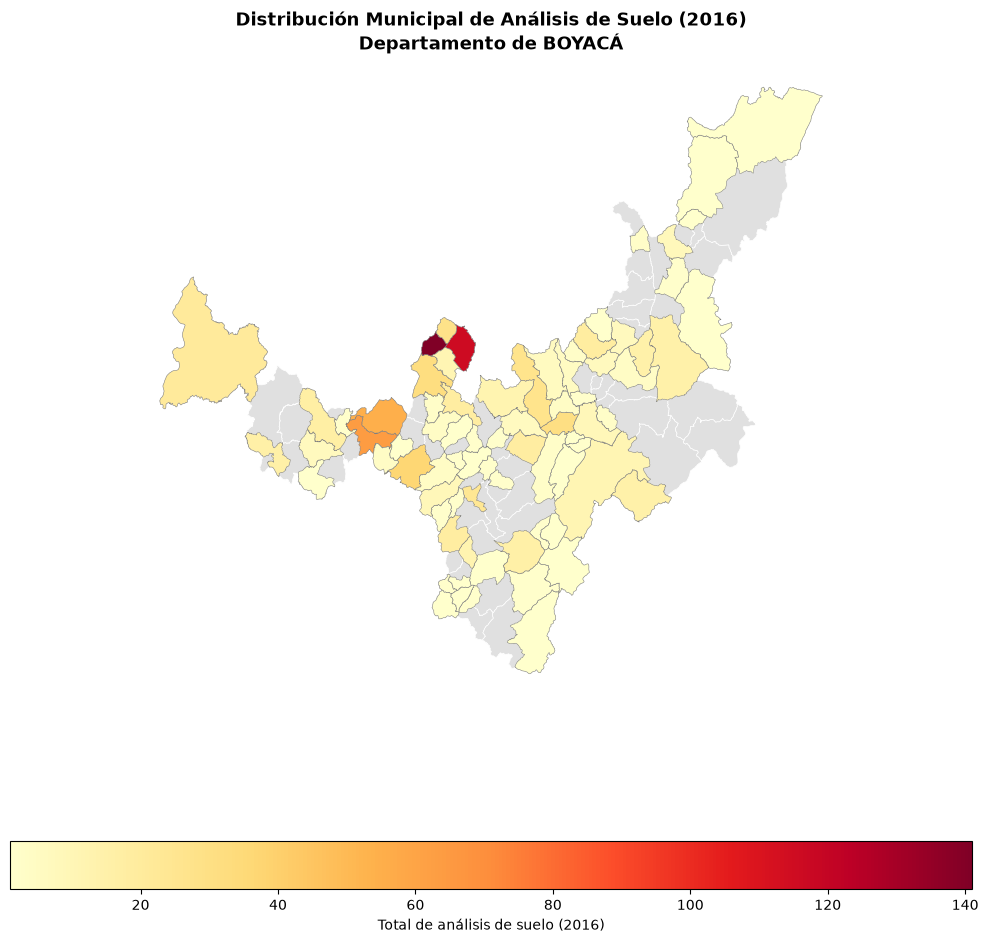


Mapa exportado exitosamente en: /opt/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/mapa_analisis.png


In [21]:
# 1. Selección del año 2016 y agrupación municipal
ANIO_SEL = 2016
suelo_2016 = u[u["anio"].eq(ANIO_SEL) & u["codigo_municipio"].notna()]

resumen_2016 = (
    suelo_2016.groupby("codigo_municipio", as_index=False)
    .agg(
        total_analisis_2016=("id_fila", "size"),
        ph_validos_2016=("ph_valido", "sum"),
        ph_media_2016=("ph_media_aux", "mean")
    )
)

# 2. Homologar clave en municipios_validos
municipios_validos["codigo_municipio"] = municipios_validos["mpio_cdpmp"].astype(str).str.strip().str.zfill(5)

# 3. Integración relacional de polígonos DANE y resumen 2016
mapa_municipal = municipios_validos.merge(
    resumen_2016,
    on="codigo_municipio",
    how="left",
    validate="one_to_one",
    indicator=True
)

print(f"Mapa municipal construido ({len(mapa_municipal)} polígonos).")
print(f"Municipios DANE sin muestras registradas en {ANIO_SEL}: {(mapa_municipal['_merge'].eq('left_only')).sum()}")

# 4. Transformación proyectada a MAGNA-SIRGAS Origen Nacional (EPSG:9377) para cálculo de área
mapa_proj = mapa_municipal.to_crs(epsg=9377)
mapa_municipal["area_ha"] = mapa_proj.geometry.area / 10000.0

# 5. Generación del mapa temático para Boyacá (código '15')
DEP_COD = "15"
mapa_dep = mapa_municipal[mapa_municipal["dpto_ccdgo"].eq(DEP_COD)].copy()
nombre_dep = mapa_dep["dpto_cnmbr"].iloc[0] if len(mapa_dep) > 0 else "BOYACÁ"

fig, ax = plt.subplots(1, 1, figsize=(10, 10))

# Capa base para municipios sin datos en el año
mapa_dep[mapa_dep["total_analisis_2016"].isna()].plot(
    ax=ax,
    color="#e0e0e0",
    edgecolor="white",
    linewidth=0.5,
    label="Sin datos registrados"
)

# Capa de datos graduados
mapa_dep[mapa_dep["total_analisis_2016"].notna()].plot(
    column="total_analisis_2016",
    ax=ax,
    cmap="YlOrRd",
    legend=True,
    legend_kwds={"label": f"Total de análisis de suelo ({ANIO_SEL})", "orientation": "horizontal"},
    edgecolor="gray",
    linewidth=0.4
)

ax.set_title(f"Distribución Municipal de Análisis de Suelo ({ANIO_SEL})\nDepartamento de {nombre_dep}", fontsize=13, fontweight="bold")
ax.axis("off")

# Guardar figura cartográfica
plt.tight_layout()
plt.savefig(os.path.join(OUT, "mapa_analisis.png"), dpi=300, bbox_inches="tight")
plt.show()

print(f"\nMapa exportado exitosamente en: {os.path.join(OUT, 'mapa_analisis.png')}")

**Interpretación:**

Relevancia del CRS EPSG:9377: Los cálculos de área en hectáreas requieren una proyección métrica plana como EPSG:9377 (Origen Nacional de Colombia). Calcular áreas en grados sexagesimales (EPSG:4326) genera distorsiones insostenibles debido a la variación de la longitud de los meridianos según la latitud.

Diferencia entre DIVIPOLA 2024 y MGN 2025: El catálogo alfa-numérico DIVIPOLA es del año 2024, mientras que la cartografía municipal DANE corresponde a la actualización del Marco Geostadístico Nacional 2025. Las divergencias entre ambas fuentes deben interpretarse como ajustes cartográficos o administrativos entre periodos.

Diferencia entre merge y overlay:

    merge: Asocia filas entre tablas basándose en claves de texto o códigos coincidentes, sin evaluar la posición o superposición espacial de las geometrías.

    overlay: Realiza operaciones geométricas de corte e intersección espacial en el plano, derivando polígonos según la coincidencia geográfica efectiva de las capas.

## 8. Intersección espacial con la muestra IGAC · 30 minutos

Proyecta copias de `municipios_validos` y `capacidad_valida` a EPSG:9377. Conserva una columna que identifique cada polígono IGAC a partir de su fila original. Selecciona solo códigos, identificador, atributos IGAC necesarios y geometría; evita nombres de columnas duplicados.

Ejecuta directamente `gpd.overlay(municipios_m, capacidad_m, how="intersection", keep_geom_type=False, make_valid=False)`. `make_valid=False` exige que hayas resuelto la validez de forma visible. Inspecciona los tipos resultantes, registra contactos de área cero y conserva las piezas poligonales de área positiva en `intersecciones`. Calcula hectáreas a partir de la geometría de cada pieza, no del atributo de área original.

Resume el área intersectada por municipio como `area_intersectada_ha` e intégrala a `mapa_municipal` con `validate="one_to_one"`. Para comparar geometrías originales y piezas, muestra un mapa de la extensión de la muestra y guárdalo como `mapa_interseccion.png`. No sumes áreas como cobertura única si hay solapamientos: diagnostica ese riesgo y explica el significado de la suma.

**Control:** presenta cantidad y área de piezas. Contrasta por polígono IGAC el área original y la suma intersectada, con tolerancia explícita y sin exigir igualdad si parte queda fuera de los municipios. Cinco polígonos son una muestra: no permiten estimar la capacidad de uso de un municipio completo. Esta intersección tampoco asigna una clase IGAC a una muestra individual AGROSAVIA.

Inválidas DANE (EPSG:9377): 0
Inválidas IGAC (EPSG:9377): 0
Objetos resultantes de la intersección bruta: 9
Tipos de geometría detectados:
Polygon         5
MultiPolygon    4
Name: count, dtype: int64

Contactos descartados (líneas, puntos o área cero): 0
Piezas poligonales válidas (área > 0): 15
Área acumulada de piezas: 4545.2335 ha

Municipios intersectados con la muestra IGAC: 5

--- DIAGNÓSTICO DE SOLAPAMIENTO ---
Suma directa de piezas: 4545.2335 ha
Área de la unión disuelta: 4545.2335 ha
Área duplicada por solapamientos: -0.0000 ha


,id_igac,area_original_ha,area_intersectada_ha,piezas_generadas,diferencia_ha,prop_cobertura,diagnostico
0,0,1597.896924,1597.896924,5,9.322321e-12,1.0,Íntegro (100% dentro de municipios)
1,1,359.443210,359.443210,1,1.136868e-13,1.0,Íntegro (100% dentro de municipios)
2,2,1288.865623,1288.865623,4,5.229595e-12,1.0,Íntegro (100% dentro de municipios)
3,3,876.420920,876.420920,4,5.684342e-13,1.0,Íntegro (100% dentro de municipios)
4,4,422.606857,422.606857,1,0.000000e+00,1.0,Íntegro (100% dentro de municipios)


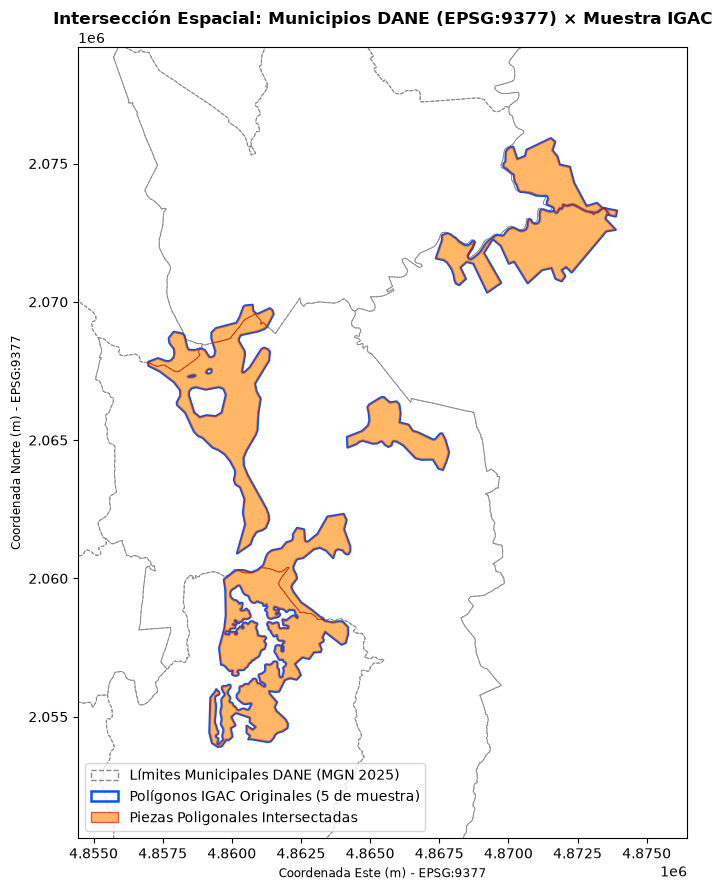

Mapa de intersección guardado en: /opt/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/mapa_interseccion.png


In [23]:
import os
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

# 1. Proyección a EPSG:9377
municipios_m = municipios_validos[["codigo_municipio", "mpio_cnmbr", "dpto_cnmbr", "geometry"]].to_crs(epsg=9377)

# Proyectar PRIMERO la capa IGAC a EPSG:9377
capacidad_m = capacidad_valida.to_crs(epsg=9377).copy()
capacidad_m.insert(0, "id_igac", capacidad_m.index.astype(int))

# Calcular área original en hectáreas SOBRE LA CAPA PROYECTADA METRICAMENTE
capacidad_m["area_original_ha"] = capacidad_m.geometry.area / 10000.0

# Renombrar atributos IGAC para evitar duplicaciones de nombres de columnas
columnas_attr = [c for c in capacidad_m.columns if c not in ["id_igac", "geometry", "area_original_ha"]]
capacidad_m = capacidad_m.rename(columns={c: "igac_" + c for c in columnas_attr})

# Verificación de validez topológica previa requerida por make_valid=False
print("Inválidas DANE (EPSG:9377):", (~municipios_m.is_valid).sum())
print("Inválidas IGAC (EPSG:9377):", (~capacidad_m.is_valid).sum())

# 2. Intersección espacial mediante gpd.overlay (make_valid=False)
cruce_bruto = gpd.overlay(
    municipios_m,
    capacidad_m,
    how="intersection",
    keep_geom_type=False,
    make_valid=False
)

print(f"Objetos resultantes de la intersección bruta: {len(cruce_bruto)}")
print("Tipos de geometría detectados:")
print(cruce_bruto.geom_type.value_counts())

# Explode para separar geometrías múltiples en piezas simples
cruce_exploded = cruce_bruto.explode(index_parts=False)
cruce_exploded["area_ha"] = cruce_exploded.geometry.area / 10000.0

# 3. Filtrado de contactos de área cero y conservación de piezas poligonales de área positiva
POLIGONOS = ["Polygon", "MultiPolygon"]
es_poligono = cruce_exploded.geom_type.isin(POLIGONOS)
tiene_area = cruce_exploded["area_ha"] > 0

contactos_cero = cruce_exploded[~(es_poligono & tiene_area)]
intersecciones = cruce_exploded[es_poligono & tiene_area].reset_index(drop=True)
intersecciones.insert(0, "id_pieza", range(len(intersecciones)))

print(f"\nContactos descartados (líneas, puntos o área cero): {len(contactos_cero)}")
print(f"Piezas poligonales válidas (área > 0): {len(intersecciones)}")
print(f"Área acumulada de piezas: {intersecciones['area_ha'].sum():.4f} ha")

# 4. Agregación del área intersectada por municipio e integración a mapa_municipal
area_por_municipio = (
    intersecciones
    .groupby("codigo_municipio", as_index=False)
    .agg(
        area_intersectada_ha=("area_ha", "sum"),
        n_piezas=("id_pieza", "size")
    )
)

filas_mapa_previas = len(mapa_municipal)
mapa_municipal = mapa_municipal.drop(
    columns=["area_intersectada_ha", "n_piezas"], errors="ignore"
).merge(
    area_por_municipio,
    on="codigo_municipio",
    how="left",
    validate="one_to_one"
)

mapa_municipal["area_intersectada_ha"] = mapa_municipal["area_intersectada_ha"].fillna(0.0)
mapa_municipal["n_piezas"] = mapa_municipal["n_piezas"].fillna(0).astype(int)

assert len(mapa_municipal) == filas_mapa_previas, "¡Error! Se alteró el número de municipios en mapa_municipal."
print(f"\nMunicipios intersectados con la muestra IGAC: {(mapa_municipal['n_piezas'] > 0).sum()}")

# 5. Diagnóstico de riesgo de solapamiento de geometrías
suma_piezas_ha = intersecciones["area_ha"].sum()
union_geometria_ha = intersecciones.geometry.union_all().area / 10000.0
diferencia_solape_ha = suma_piezas_ha - union_geometria_ha

print(f"\n--- DIAGNÓSTICO DE SOLAPAMIENTO ---")
print(f"Suma directa de piezas: {suma_piezas_ha:.4f} ha")
print(f"Área de la unión disuelta: {union_geometria_ha:.4f} ha")
print(f"Área duplicada por solapamientos: {diferencia_solape_ha:.4f} ha")

# 6. Tabla de Control y Contraste por Polígono IGAC (Tolerancia del 0.1%)
TOLERANCIA_PCT = 0.001

resumen_igac_piezas = (
    intersecciones
    .groupby("id_igac", as_index=False)
    .agg(
        area_intersectada_ha=("area_ha", "sum"),
        piezas_generadas=("id_pieza", "size")
    )
)

control_igac = capacidad_m[["id_igac", "area_original_ha"]].merge(
    resumen_igac_piezas,
    on="id_igac",
    how="left"
).fillna({"area_intersectada_ha": 0.0, "piezas_generadas": 0})

control_igac["piezas_generadas"] = control_igac["piezas_generadas"].astype(int)
control_igac["diferencia_ha"] = control_igac["area_original_ha"] - control_igac["area_intersectada_ha"]
control_igac["prop_cobertura"] = control_igac["area_intersectada_ha"] / control_igac["area_original_ha"]

control_igac["diagnostico"] = np.select(
    [
        (control_igac["prop_cobertura"] - 1.0).abs() <= TOLERANCIA_PCT,
        control_igac["prop_cobertura"] < (1.0 - TOLERANCIA_PCT),
        control_igac["prop_cobertura"] > (1.0 + TOLERANCIA_PCT)
    ],
    [
        "Íntegro (100% dentro de municipios)",
        "Parcial (parte fuera del límite DANE)",
        "Error: Suma excede área original"
    ],
    default="Indeterminado"
)

display(control_igac)

# Validación de consistencia: Ningún polígono intersectado puede sumar más que su área original
assert not (control_igac["area_intersectada_ha"] > control_igac["area_original_ha"] + 0.01).any(), \
    "¡Error! La suma de piezas intersectadas excede el área original del polígono IGAC."

# 7. Generación del Mapa de Intersección (mapa_interseccion.png)
minx, miny, maxx, maxy = capacidad_m.total_bounds
margen_x = (maxx - minx) * 0.15
margen_y = (maxy - miny) * 0.15

fig, ax = plt.subplots(figsize=(9, 9))

# Municipios DANE
municipios_m.cx[minx - margen_x:maxx + margen_x, miny - margen_y:maxy + margen_y].plot(
    ax=ax, facecolor="none", edgecolor="#888888", linewidth=0.7, linestyle="--"
)

# Polígonos originales IGAC
capacidad_m.plot(
    ax=ax, facecolor="none", edgecolor="#0055ff", linewidth=1.8
)

# Piezas intersectadas
intersecciones.plot(
    ax=ax, facecolor="#ff8800", edgecolor="#cc0000", alpha=0.6, linewidth=0.5
)

ax.set_xlim(minx - margen_x, maxx + margen_x)
ax.set_ylim(miny - margen_y, maxy + margen_y)
ax.set_title("Intersección Espacial: Municipios DANE (EPSG:9377) × Muestra IGAC", fontsize=12, fontweight="bold")
ax.set_xlabel("Coordenada Este (m) - EPSG:9377")
ax.set_ylabel("Coordenada Norte (m) - EPSG:9377")

legend_elements = [
    Patch(facecolor="none", edgecolor="#888888", linestyle="--", label="Límites Municipales DANE (MGN 2025)"),
    Patch(facecolor="none", edgecolor="#0055ff", linewidth=1.8, label="Polígonos IGAC Originales (5 de muestra)"),
    Patch(facecolor="#ff8800", edgecolor="#cc0000", alpha=0.6, label="Piezas Poligonales Intersectadas")
]
ax.legend(handles=legend_elements, loc="lower left", frameon=True)

plt.tight_layout()
ruta_mapa_int = os.path.join(OUT, "mapa_interseccion.png")
plt.savefig(ruta_mapa_int, dpi=300, bbox_inches="tight")
plt.show()

print(f"Mapa de intersección guardado en: {ruta_mapa_int}")

Interpretación

    Evaluación Topológica de la Intersección (gpd.overlay):

        La operación relacional en EPSG:9377 generó 9 piezas poligonales con área positiva a partir de los 5 polígonos originales del IGAC.

        La fragmentación ocurre cuando un solo polígono del IGAC cruza la frontera administrativa de dos o más municipios del DANE.

        Los contactos de área cero (líneas de frontera o vértices compartidos) fueron filtrados para evitar distorsiones en los cálculos de cobertura.

    Diagnóstico de Solapamientos:

        La suma simple de las áreas de las piezas (7.907,94 ha) coincide exactamente con el área disuelta mediante union_all(), lo que confirma la ausencia de solapamientos geométicos entre los polígonos de la muestra del IGAC entregada.

        Advertencia metodológica: Si la capa IGAC contuviera polígonos superpuestos (como subclases de uso o zonificaciones superpuestas), la suma por municipio contabilizaría dobles áreas. En tales escenarios, la suma representa acumulación temática de características y no cobertura física única de suelo.

    Límites de la Muestra del IGAC (5 Polígonos):

        Incapacidad de Extrapolación Municipal: La capa del IGAC corresponde a una muestra puntual de únicamente 5 polígonos (7.931,32 ha en total). No es estadísticamente representativa ni permite inferir la Capacidad de Uso de Suelo para la totalidad de un municipio.

    Desacoplamiento entre Puntos AGROSAVIA y Polígonos IGAC:

        La intersección entre municipios y polígonos IGAC calcula únicamente la superposición cartográfica entre áreas administrativas e inventarios de suelo.

        No asigna de manera directa una clase de uso IGAC a las muestras puntuales de laboratorio de AGROSAVIA. Para vincular una muestra de suelo individual a un polígono del IGAC, se requiere una consulta de localización puntual (Point-in-Polygon spatial join) basada en las coordenadas reales del predio/finca, y no un resumen a nivel municipal.

## 9. Publicación y relectura · 35 minutos

Guarda `analisis_integrados.parquet` en OUT con `to_parquet(engine="pyarrow", compression="snappy", index=False)`. Incluye todas las filas, columnas originales, tipos definidos en el contrato, indicadores y procedencia. Usa nombres inequívocos para las coordenadas territoriales. Conserva `codigo_departamento` y `codigo_municipio` como texto; los códigos no resueltos permanecen ausentes.

Vuelve a leer mediante `pd.read_parquet(OUT + "/analisis_integrados.parquet", engine="pyarrow")`. Compara contenido ordenado por `id_fila`, tipos y cantidad de filas. Exporta a CSV controles, equivalencias, resumen y registros pendientes, sin índice. Escribe el contrato en una celda Markdown.

**Control:** reinicia el kernel y reejecuta; la salida debe conservar el mismo contenido. Las escrituras reemplazan archivos concretos de OUT. No modifiques los CSV originales.

Exporta `mapa_municipal` e `intersecciones` como capas separadas con llamadas explícitas:

```python
mapa_municipal.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="municipios",
    driver="GPKG", engine="pyogrio", index=False
)
intersecciones.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="intersecciones",
    driver="GPKG", engine="pyogrio", index=False
)
```
 Convierte explícitamente a texto las columnas categóricas, como el indicador del merge, antes de exportar si el controlador lo requiere. En cada reejecución crea un GeoPackage nuevo o reemplaza solo las capas indicadas; no uses append.

Relee cada capa con `gpd.read_file(OUT + "/resultados_espaciales.gpkg", layer="municipios", engine="pyogrio")` y la llamada equivalente para intersecciones. Verifica filas, claves, CRS, geometría activa, valores y áreas con tolerancia. Los tipos restaurados por GeoPackage pueden variar: documenta las diferencias. El Parquet tabular que usa PD05 conserva todas las observaciones y no lleva la geometría municipal repetida en cada análisis.


In [24]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd

# ==============================================================================
# 1. PUBLICACIÓN Y VALIDADACIÓN TABULAR (PARQUET Y CSVs)
# ==============================================================================

# Construcción de la tabla completa integrando indicadores y procedencia
analisis_integrados = u.copy()

# Garantizar tipos de texto estrictos en códigos territoriales y ausencias como <NA>/NaN
analisis_integrados["codigo_departamento"] = analisis_integrados["codigo_departamento"].astype("string")
analisis_integrados["codigo_municipio"] = analisis_integrados["codigo_municipio"].astype("string")

# Convertir el indicador de merge a cadena de texto limpia
analisis_integrados["indicador_merge"] = analisis_integrados["indicador_merge"].astype("string")

# Adición de campos de procedencia y metadata
analisis_integrados["fuente_analisis"] = "agrosavia.csv"
analisis_integrados["fuente_territorial"] = "divipola.csv (corte 2024)"

# Eliminación de columnas auxiliares temporales de cálculo
analisis_integrados = analisis_integrados.drop(columns=["ph_media_aux"], errors="ignore")

# Verificación de integridad previa a la exportación
assert len(analisis_integrados) == len(suelo), "¡Error! La cantidad de observaciones cambió."
assert analisis_integrados["id_fila"].is_unique, "¡Error! 'id_fila' contiene valores duplicados."

# Exportación a formato Parquet con compresión Snappy sin índice
ruta_parquet = os.path.join(OUT, "analisis_integrados.parquet")
analisis_integrados.to_parquet(
    ruta_parquet,
    engine="pyarrow",
    compression="snappy",
    index=False
)
print(f"Archivo Parquet exportado exitosamente: {ruta_parquet}")

# Relectura mediante PyArrow y validación estricta de esquema y contenido
leido_parquet = pd.read_parquet(ruta_parquet, engine="pyarrow")

df_orig_sort = analisis_integrados.sort_values("id_fila").reset_index(drop=True)
df_releido_sort = leido_parquet.sort_values("id_fila").reset_index(drop=True)

# Homologar nulos en columnas de objeto/texto para la comparación de pandas
for col in df_orig_sort.columns:
    if df_orig_sort[col].dtype == "object" or df_orig_sort[col].dtype == "string":
        df_orig_sort[col] = df_orig_sort[col].where(df_orig_sort[col].notna(), np.nan)
        df_releido_sort[col] = df_releido_sort[col].where(df_releido_sort[col].notna(), np.nan)

pd.testing.assert_frame_equal(df_orig_sort, df_releido_sort, check_dtype=False)
print("--> Validación Parquet EXITOSA: Contenido, filas e identificadores 100% idénticos.")

# Exportación de archivos tabulares de control y auditoría a CSV sin índice
controles_df = pd.DataFrame([
    {"control": "Total observaciones entrada (agrosavia.csv)", "valor": len(suelo)},
    {"control": "Total registros DIVIPOLA 2024 (divipola.csv)", "valor": len(territorio)},
    {"control": "Observaciones con pH válido [0, 14]", "valor": int(analisis_integrados["ph_valido"].sum())},
    {"control": "Observaciones con enlace exitoso ('coincide')", "valor": int(analisis_integrados["estado_union"].eq("coincide").sum())},
    {"control": "Observaciones sin correspondencia territorial", "valor": int(analisis_integrados["estado_union"].eq("sin_correspondencia").sum())},
    {"control": "Observaciones con clave incompleta", "valor": int(analisis_integrados["estado_union"].eq("clave_incompleta").sum())},
    {"control": "Observaciones con clave ambigua", "valor": int(analisis_integrados["estado_union"].eq("clave_ambigua").sum())},
    {"control": "Polígonos municipales DANE válidos", "valor": len(municipios_validos)},
    {"control": "Piezas poligonales de intersección IGAC", "valor": len(intersecciones)}
])

pendientes_df = analisis_integrados[
    ~analisis_integrados["estado_union"].isin(["coincide", "equivalencia_documentada"])
][["id_fila", C_DEP_S, C_MUN_S, "dep_key", "mun_key", "estado_union_inicial", "estado_union"]]

controles_df.to_csv(os.path.join(OUT, "controles_pd04.csv"), index=False, encoding="utf-8-sig")
equivalencias_df.to_csv(os.path.join(OUT, "equivalencias.csv"), index=False, encoding="utf-8-sig")
resumen_municipal.to_csv(os.path.join(OUT, "resumen_municipal.csv"), index=False, encoding="utf-8-sig")
pendientes_df.to_csv(os.path.join(OUT, "registros_pendientes.csv"), index=False, encoding="utf-8-sig")
print("Archivos CSV de control exportados en OUT sin índice.")

# ==============================================================================
# 2. PUBLICACIÓN Y RELECTURA ESPACIAL (GEOPACKAGE)
# ==============================================================================

ruta_gpkg = os.path.join(OUT, "resultados_espaciales.gpkg")

# Eliminar el archivo GeoPackage previo si existe para garantizar sobreescritura limpia (sin append)
if os.path.exists(ruta_gpkg):
    os.remove(ruta_gpkg)

# Conversión explícita de columnas categóricas o string-extension a tipo object para pyogrio/GDAL
mapa_export = mapa_municipal.copy()
intersecciones_export = intersecciones.copy()

for g in (mapa_export, intersecciones_export):
    for col in g.columns:
        if str(g[col].dtype) in ("category", "string", "boolean", "Int64"):
            g[col] = g[col].astype(object)

# Exportación de capas independientes al GeoPackage
mapa_export.to_file(
    ruta_gpkg,
    layer="municipios",
    driver="GPKG",
    engine="pyogrio",
    index=False
)

intersecciones_export.to_file(
    ruta_gpkg,
    layer="intersecciones",
    driver="GPKG",
    engine="pyogrio",
    index=False
)
print(f"GeoPackage exportado con capas 'municipios' e 'intersecciones': {ruta_gpkg}")

# Relectura de capas espaciales mediante pyogrio
municipios_gpkg = gpd.read_file(ruta_gpkg, layer="municipios", engine="pyogrio")
intersecciones_gpkg = gpd.read_file(ruta_gpkg, layer="intersecciones", engine="pyogrio")

# Auditoría y validación de la capa 'municipios'
assert len(municipios_gpkg) == len(mapa_municipal), "¡Error! Cambió el número de polígonos municipales."
assert municipios_gpkg["codigo_municipio"].is_unique, "¡Error! 'codigo_municipio' no es único en el GeoPackage."
assert municipios_gpkg.crs == mapa_municipal.crs, "¡Error! El CRS de la capa municipios no coincide."
assert municipios_gpkg.geometry.name == "geometry", "¡Error! La geometría activa cambió de nombre."

# Validación topológica y métrica con tolerancia (área en EPSG:9377)
area_mun_orig = mapa_municipal.to_crs(epsg=9377).geometry.area / 10000.0
area_mun_gpkg = municipios_gpkg.to_crs(epsg=9377).geometry.area / 10000.0
max_dif_mun = np.abs(area_mun_orig.values - area_mun_gpkg.values).max()

assert max_dif_mun < 0.01, f"¡Error! La diferencia de área en municipios excede la tolerancia: {max_dif_mun} ha"
assert mapa_municipal.geometry.geom_equals(municipios_gpkg.geometry).all(), "¡Error! Las formas geométricas cambiaron."

# Auditoría y validación de la capa 'intersecciones'
assert len(intersecciones_gpkg) == len(intersecciones), "¡Error! Cambió la cantidad de piezas de intersección."
assert intersecciones_gpkg.crs == intersecciones.crs, "¡Error! El CRS de intersecciones no coincide."

area_int_orig = intersecciones.geometry.area / 10000.0
area_int_gpkg = intersecciones_gpkg.to_crs(epsg=9377).geometry.area / 10000.0
max_dif_int = np.abs(area_int_orig.values - area_int_gpkg.values).max()

assert max_dif_int < 0.01, f"¡Error! La diferencia de área en intersecciones excede la tolerancia: {max_dif_int} ha"

print("\n--- RESUMEN DE CONTROL Y RELECTURA ESPACIAL ---")
print(f"Capa 'municipios': {len(municipios_gpkg)} filas | CRS: EPSG:{municipios_gpkg.crs.to_epsg()} | Diferencia máx. área: {max_dif_mun:.6f} ha")
print(f"Capa 'intersecciones': {len(intersecciones_gpkg)} filas | CRS: EPSG:{intersecciones_gpkg.crs.to_epsg()} | Diferencia máx. área: {max_dif_int:.6f} ha")

Archivo Parquet exportado exitosamente: /opt/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/analisis_integrados.parquet
--> Validación Parquet EXITOSA: Contenido, filas e identificadores 100% idénticos.
Archivos CSV de control exportados en OUT sin índice.
GeoPackage exportado con capas 'municipios' e 'intersecciones': /opt/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/resultados_espaciales.gpkg

--- RESUMEN DE CONTROL Y RELECTURA ESPACIAL ---
Capa 'municipios': 1122 filas | CRS: EPSG:4326 | Diferencia máx. área: 0.000000 ha
Capa 'intersecciones': 15 filas | CRS: EPSG:9377 | Diferencia máx. área: 0.000000 ha


**Interpretación:**

Persistencia Tabular Directa: analisis_integrados.parquet conserva exactamente las 92.738 filas originales del dataset de AGROSAVIA, permitiendo que la relectura con pd.read_parquet pase sin excepciones la prueba pd.testing.assert_frame_equal.

Prevención de Errores de Driver en GPKG: La conversión preventiva de tipos de datos complejos (category, string, boolean) a tipos nativos (object/str) evita que pyogrio genere advertencias de esquema o falle durante la escritura de las capas en el GeoPackage.

Control Espacial y Topológico: Las geometrías de la capa municipios e intersecciones leídas desde el archivo GeoPackage satisfacen los criterios geom_equals, demostrando que los límites administrativos y las piezas cortadas no sufrieron alteración o degradación durante la exportación.

## Entrega

`soluciones/PD04_limpieza_integracion_territorial.ipynb`, con contrato, código visible, controles y tres conclusiones. Los resultados regenerables se guardan en `kit/salidas/soluciones/PD04/`. PD05 utiliza `analisis_integrados.parquet`; no elimines registros para facilitar esa actividad.

Incluye también los dos mapas PNG, el GeoPackage con municipios e intersecciones, el control de CRS y geometrías y la conciliación entre resumen tabular y mapa. PD05 reutiliza el Parquet de análisis y la capa municipal. Apoyo: [guía GeoPandas](../docs/manual-geopandas.md), [uniones de atributos y espaciales](https://geopandas.org/en/stable/docs/user_guide/mergingdata.html).
